In [1]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colors
from scipy.interpolate import griddata, RegularGridInterpolator, CubicSpline
import pygeode as pyg
import os, glob, sys
sys.path.append("..")
from jfunctions import *
from mpas_funcs import *
import scipy.ndimage
from matplotlib.lines import Line2D
from tropopause import *

%matplotlib widget

save = False
#save_dir='/home/cwp29/tmp/mpas/T_nudge/'

In [2]:
root_dir = '/store/atmos-adk33/cwp29/mpas-a/data/trop_ref/'

sim_dirs = ['microp_re_test', 'control']
sim_names = ['m', 'c']

In [3]:
def lat_mean(da, lat_dim='latitude'):
    w = np.cos(np.deg2rad(da[lat_dim]))
    return da.weighted(w).mean(dim=lat_dim)

def lon_mean(da, save_dir, fname, force_compute=False, lon_dim='longitude'):
    if os.path.exists(os.path.join(sim_dir, fname)) and not fc:
        return np.load(os.path.join(sim_dir, fname))
    else:
        save_var = da.mean(dim='longitude').values
        np.save(os.path.join(sim_dir, fname), save_var)
        return save_var
    
def zonal_mean(da, save_dir, fname, force_compute=False):
    if os.path.exists(os.path.join(save_dir, fname)) and not force_compute:
        return np.load(os.path.join(save_dir, fname))
    else:
        save_var = da.mean(dim=('longitude', 'Time')).values
        np.save(os.path.join(save_dir, fname), save_var)
        return save_var
        
def trop_profile(da, save_dir, fname, force_compute=False):
    if os.path.exists(os.path.join(save_dir, fname)) and not force_compute:
        return np.load(os.path.join(save_dir, fname))
    else:
        save_var = lat_mean(da.sel(latitude=slice(-10, 10))).mean('longitude', 'Time').values
        np.save(os.path.join(save_dir, fname), save_var)
        return save_var

In [4]:
data = {}

# change this to read iso_levels.dat
pres = np.array([100, 200, 300, 500, 700, 1000, 2000, 3000, 5000, 7000, 10000, 15000, 20000, 25000, 30000, 40000, 50000, 60000, 70000, 85000, 92500, 100000], dtype=np.float64)
pres /= 100

p0 = 1000 #hPa
R_cp = 0.286
g = 9.81

fc = False

for sim_dir, name in zip(sim_dirs, sim_names):
    print("Computing from %s"%sim_dir)
    # compute: time + zonal mean u, time + zonal mean T, 10N/S profiles of U and T
    zm_paths = sorted(path for path in glob.glob(os.path.join(root_dir, sim_dir, 'zm_latlon*.nc')) if '_spinup' not in os.path.basename(path))
    latlon_paths = sorted(path for path in glob.glob(os.path.join(root_dir, sim_dir, 'latlon*.nc')) if '_spinup' not in os.path.basename(path))
    ds_zm = xr.open_mfdataset(zm_paths)
    ds = xr.open_mfdataset(latlon_paths)
    temp = ds_zm.theta * (ds_zm.pressure / (100*p0))**R_cp

    Ubar_t = ds_zm.uReconstructZonal.values

    Tprofile = lat_mean(temp.sel(latitude=slice(-10, 10))).mean(dim='Time')
    Uprofile = lat_mean(ds_zm.uReconstructZonal.sel(latitude=slice(-10, 10))).mean(dim='Time')

    thetabar = ds_zm.theta.mean(dim='Time')

    N2 = g * ds_zm.theta.differentiate('z') / ds_zm.theta
    stab = lat_mean(N2.sel(latitude=slice(-10, 10))).mean(dim='Time')
    
    Tbar = temp.mean(dim='Time')
    Ubar = ds_zm.uReconstructZonal.mean(dim='Time')
    #Vbar = ds_zm.uReconstructMeridional.mean(dim='Time') 
    #cfbar = zonal_mean(ds.cldfrac, os.path.join(root_dir, sim_dir), 'cfracbar', force_compute=fc).mean(dim='Time')

    # shear
    # Don't have meridional velocity, add this later ...
    #speed = np.hypot(Ubar, Vbar)
    shear = Ubar.differentiate('z')
    vshearbar = lat_mean(shear.sel(latitude=slice(-10, 10)))
        
    # Store data for plotting
    data[name] = {
        'Time': ds.Time.values,
        'Tbar' : Tbar,
        'Tprofile' : Tprofile,
        'Ubar' : Ubar,
        'Ubar_t' : Ubar_t,
        'Uprofile' : Uprofile,
        'stability' : stab,
        #'cldfrac' : cfbar,
        'shear': vshearbar,
        'theta': thetabar,
        'config' : get_config(os.path.join(root_dir, sim_dir))
    }

Computing from microp_re_test
namelist.atmosphere not found in directory /store/atmos-adk33/cwp29/mpas-a/data/trop_ref/microp_re_test
Computing from control
namelist.atmosphere not found in directory /store/atmos-adk33/cwp29/mpas-a/data/trop_ref/control


In [5]:
print(ds)
print(ds_zm)

<xarray.Dataset> Size: 991GB
Dimensions:                 (latitude: 360, longitude: 720, Time: 595,
                             nVertLevelsP1: 76, nVertLevels: 75,
                             nIsoLevelsT: 22, nIsoLevelsZ: 22, nIsoLevelsU: 22)
Coordinates:
  * latitude                (latitude) float32 1kB -89.75 -89.25 ... 89.25 89.75
  * longitude               (longitude) float32 3kB -179.8 -179.2 ... 179.8
  * Time                    (Time) datetime64[ns] 5kB 2000-05-05T06:00:00 ......
Dimensions without coordinates: nVertLevelsP1, nVertLevels, nIsoLevelsT,
                                nIsoLevelsZ, nIsoLevelsU
Data variables: (12/49)
    zgrid                   (Time, nVertLevelsP1, latitude, longitude) float32 47GB dask.array<chunksize=(107, 76, 360, 720), meta=np.ndarray>
    zz                      (Time, nVertLevels, latitude, longitude) float32 46GB dask.array<chunksize=(107, 75, 360, 720), meta=np.ndarray>
    u                       (Time, nVertLevels, latitude, longitud

In [6]:
# Let's assume these are identical across all datasets...

lats = ds.latitude.values
lons = ds.longitude.values

zs = ds_zm.z.values
zs_hres = np.linspace(0, np.max(zs), 256)

ps = lat_mean(ds_zm.pressure).mean('Time').values/100

def pres_to_alt(p):
    return np.interp(p, ps[::-1], zs[::-1])

In [7]:
# plot tropopause

def plot_CPT(ax, Tbar, ls='-', col='k', lw=1, label=False, alpha=1.0):
    nzoom = 25
    Tbar = scipy.ndimage.zoom(Tbar, nzoom)
    CPT_mask = Tbar - np.min(Tbar, axis=0)[np.newaxis, :]
    CPT_im = ax.contour(scipy.ndimage.zoom(lats, nzoom), scipy.ndimage.zoom(ps, nzoom), CPT_mask, levels=[0], colors=col, linestyles=ls, linewidths=1, alpha=alpha)
    
def plot_CPT2(ax, Tbar, ls='-', col='k', lw=1, label=False, alpha=1.0):
    ztps = []
    ptps = []
    for i in range(len(lats)):
        ttp, ptp, ztp, _ = tropopause_profile(Tbar[2:, i], ps[2:], zs[2:])
        ztps.append(ztp)
        ptps.append(ptp)
        
    ax.plot(lats, ptps, color=col, ls=ls, lw=lw, alpha=alpha)
    
def plot_LPT(ax, Tbar, ls='-', col='k'):
    dTdz = np.gradient(Tbar, zs/1e3, axis=0) # K/km
    LPT_mask = np.where(dTdz < 2, 1, -1)
    ax.contour(lats, ps, LPT_mask, levels=[0], colors=col, linestyles=ls)

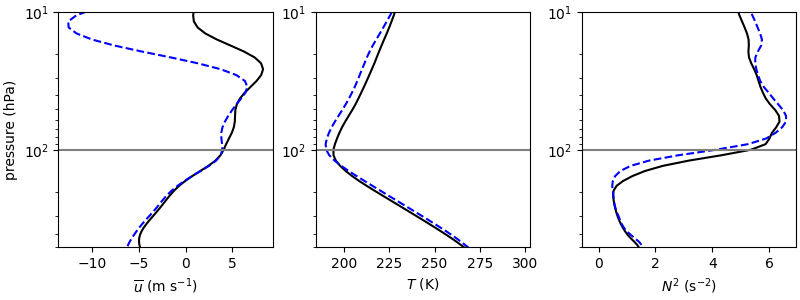

In [8]:
# Compare 1D profiles of u, T, N^2

styles = ['-', '--', ':']
from diagnostics.analysis_config import ALL_SIMULATION_LABELS, simulation_colour
cols = ['b', simulation_colour('control')]
titles = ['Microphysics test', ALL_SIMULATION_LABELS['control']]

fig, axs = plt.subplots(1, 3, figsize=(8, 3), constrained_layout=True)

for i, name in enumerate(sim_names):
    axs[0].plot(data[name]['Uprofile'], ps, color=cols[i], ls=styles[i])
    
    axs[1].plot(data[name]['Tprofile'], ps, color=cols[i], ls=styles[i])
    
    axs[2].plot(data[name]['stability']/1e-4, ps, color=cols[i], ls=styles[i])

axs[0].set_xlabel(r"$\overline{u}$ (m s$^{-1}$)")
axs[1].set_xlabel(r"$T$ (K)")
axs[2].set_xlabel(r"$N^2$ (s$^{-2}$)")

axs[0].set_ylabel(r"pressure (hPa)")

for a in axs:
    a.set_yscale('log')
    a.set_ylim(10, 500)
    a.invert_yaxis()
    a.axhline(100, color='grey')

TypeError: Input z must be at least a (2, 2) shaped array, but has shape (75, 0)

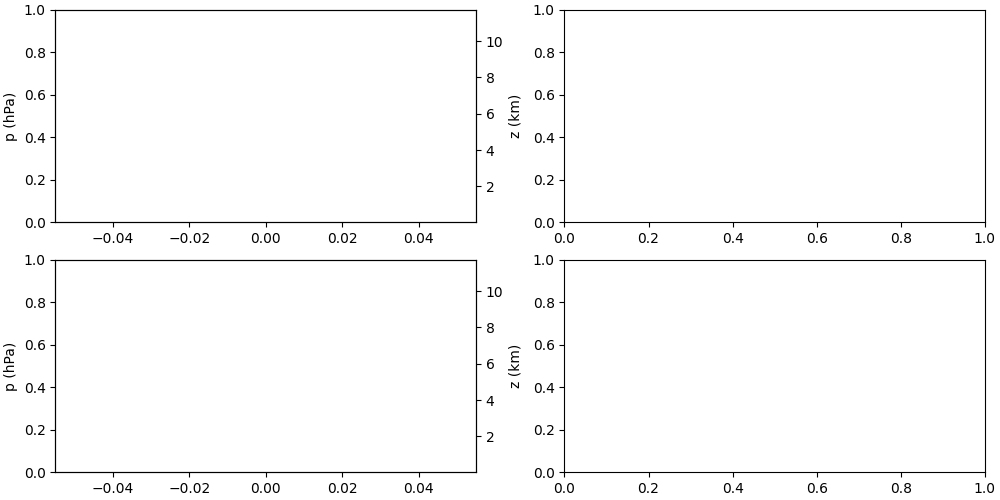

In [9]:
# Compare 2D cross-sections

fig, ax = plt.subplots(2, 2, figsize=(10, 5), constrained_layout=True)

Tlevs = np.arange(190, 305, 5)
Ulevs = np.arange(-20, 55, 5)

p_top = 2e2
p_btm = 1000e2

for i, name in enumerate(sim_names):
    ax[0, 0].set_ylabel("p (hPa)")
    ax[1, 0].set_ylabel("p (hPa)")
    
    # show altitude alongside pressure
    if i == 0:
        for r in range(2):
            alt_ax = ax[r, 0].twinx()
            alt_ax.plot(np.zeros_like(data[name]['Tprofile']), zs/1e3, alpha=0)
            alt_ax.set_ylim(pres_to_alt(p_btm)/1e3, pres_to_alt(p_top)/1e3)
            alt_ax.set_ylabel("z (km)")

    # u and T zonal means
    if name != 'c':
        T_im = ax[0, i].contourf(lats, ps, data[name]['Tbar']-data['c']['Tbar'], levels=np.arange(-5, 6, 1), cmap='coolwarm', extend='both')
        ax[0, i].contour(lats, ps, data[name]['Ubar']-data['c']['Ubar'], levels=np.arange(2, 11, 2), colors='g', linewidths=0.5)
        ax[0, i].contour(lats, ps, data[name]['Ubar']-data['c']['Ubar'], levels=np.arange(-10, -1, 2), colors='g', linewidths=0.5, linestyles=['--'])
        ax[0, i].set_title(titles[i]+' - control')

        if i == 2:
            fig.colorbar(T_im, ax=ax[0, i], label=r'$\Delta \overline{T}$ (K)', location='right')
    else:
        T_im = ax[0, i].contourf(lats, ps, data[name]['Tbar'], levels=Tlevs, cmap='coolwarm', extend='both')
        ax[0, i].contour(lats, ps, data[name]['Ubar'], levels=Ulevs[Ulevs > 0], colors='g', linewidths=0.5)
        ax[0, i].contour(lats, ps, data[name]['Ubar'], levels=Ulevs[Ulevs < 0], colors='g', linewidths=0.5, linestyles=['--'])
        ax[0, i].set_title(titles[i])

        fig.colorbar(T_im, ax=ax[0, i], label=r'$\overline{T}$ (K)', location='right')

    # cldfrac
    #if name != 'c':
        #cf_im = ax[1, i].contourf(lats, ps, data[name]['cldfrac']-data['c']['cldfrac'], levels=np.arange(-0.1, 0.105, 0.01), cmap='bwr', extend='both')

        #if i == 2:
            #fig.colorbar(cf_im, ax=ax[1, i], label=r"$\Delta$ cloud fraction", location='right')
    #else:
        #cf_im = ax[1, i].contourf(lats, ps, data[name]['cldfrac'], levels=np.linspace(0, 1, 11), cmap='binary')

        #fig.colorbar(cf_im, ax=ax[1, i], label=r"cloud fraction", location='right')

    for a in [ax[0, i], ax[1, i]]:
        a.set_xlim(-70, 70)
        print(data[name]['Tbar'].shape)
        plot_CPT2(a, data[name]['Tbar'], label=True)
        
        if i > 0:
            plot_CPT2(a, data['c']['Tbar'], col='grey', alpha=0.5)

        theta_levels = [340, 380, 420]
        label_lat = 0
        theta_im = a.contour(lats, ps, data[name]['theta'], levels=theta_levels, colors='r', linewidths=0.5)
        a.clabel(theta_im, theta_im.levels, fontsize=8,
                 manual=[(label_lat, np.interp(t, data[name]['theta'][:, get_index(label_lat, lats)], ps)) for t in theta_levels])


legend_elements = [
    Line2D([0], [0], color='k', lw=1, label="CPT"),
    Line2D([0], [0], color='g', lw=0.5, label=r"$\overline{u}$"),
    Line2D([0], [0], color='r', lw=0.5, label=r"$\theta$")
    ]

fig.legend(handles=legend_elements, loc='outside lower center', ncols=len(legend_elements))

for a in ax.ravel():
    a.set_xlabel('Latitude (degrees)')
    a.set_yscale('log')
    a.invert_yaxis()
    a.set_ylim(p_btm/1e2, p_top/1e2)

for r in range(2):
    for c in range(1, 3):
        ax[r, c].set_yticklabels([])

save_fig(fig, '/home/cwp29/tmp/mpas/comp_sim.png', dpi=300)

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(8, 3), constrained_layout=True)

for i, name in enumerate(sim_names):
    ax[0].plot(data[name]['dTime'], scipy.ndimage.uniform_filter1d(data[name]['Ubar_t'][:, get_index(50, pres), get_index(60, lats)], size=8), color=cols[i])
    
    ax[1].plot(data[name]['dTime'], scipy.ndimage.uniform_filter1d(data[name]['Ubar_t'][:, get_index(50, pres), get_index(-60, lats)], size=8), color=cols[i], ls=':')
    
    ax[2].plot(data[name]['dTime'], scipy.ndimage.uniform_filter1d(np.mean(data[name]['Ubar_t'][:, get_index(50, pres), get_index(-5, lats):get_index(5, lats)+1], axis=1), size=8), color=cols[i])

ax[0].set_title('SPV ($\overline{u}$ at 50hPa, 60$^\circ$N)')
ax[1].set_title('SPV ($\overline{u}$ at 50hPa, 60$^\circ$S)')
ax[2].set_title('QBO ($\overline{u}$ at 50hPa, 5$^\circ$N-S)')

ax[0].set_ylim(0, 80)
ax[1].set_ylim(0, 80)
ax[2].set_ylim(-5, 5)

In [ ]:
# Wave spectra (from precip rate. Try OLR later)
from wavenumber_frequency_functions import *

min_length = np.inf
prs = []
prs_con = []
prs_res = []

for i, sim_dir in enumerate([u_dir, T_dir, control_dir]):
    print("Computing from %s"%sim_dir)
    dsd = xr.open_dataset(os.path.join(sim_dir, 'latlon_diag.nc'))
    precip = dsd.rainc + dsd.i_rainc*100. + dsd.rainnc + dsd.i_rainnc*100.
    precip = precip.sel(latitude=slice(-10, 10))
    pr = precip.differentiate("Time", datetime_unit="3h")
    pr = pr.rename({'latitude':'lat', 'longitude':'lon'})
    
    precip_con = dsd.rainc + dsd.i_rainc*100. 
    pr_con = precip_con.differentiate("Time", datetime_unit="3h")
    pr_con = pr_con.rename({'latitude':'lat', 'longitude':'lon'})
    
    precip_res = dsd.rainnc + dsd.i_rainnc*100. 
    pr_res = precip_res.differentiate("Time", datetime_unit="3h")
    pr_res = pr_res.rename({'latitude':'lat', 'longitude':'lon'})

    if len(pr.Time) < min_length:
        min_length = int(len(pr.Time))
        
    prs.append(pr)
    prs_con.append(pr_con)
    prs_res.append(pr_res)

In [ ]:
print("Computing wave spectra...")
spd = 8

fig, axs = plt.subplots(2, len(sim_names), figsize=(8, 5), constrained_layout=True)
spec_levels = np.linspace(0, 2.5, 26)

for d, sim_dir in enumerate([u_dir, T_dir, control_dir]):
    pr = prs[d].isel(Time=slice(0, min_length))
    
    raw_spectrum = spacetime_power(pr, lataggreg='sum', latitude_bounds=(-10, 10), dosymmetries=True, 
                                   segsize=96, noverlap=30, spd=8)

    sym_smooth_spectrum = smooth_wavefreq(raw_spectrum.sel(component='symmetric'), freq_ax = 1)
    asym_smooth_spectrum = smooth_wavefreq(raw_spectrum.sel(component='antisymmetric'), freq_ax = 1)
    
    sym_sig_spectrum = raw_spectrum.sel(component='symmetric')/sym_smooth_spectrum
    asym_sig_spectrum = raw_spectrum.sel(component='antisymmetric')/asym_smooth_spectrum

    wn = sym_sig_spectrum.wavenumber
    f = sym_sig_spectrum.frequency

    sym_spec_im = axs[0, d].contourf(wn, f, sym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
    
    asym_spec_im = axs[1, d].contourf(wn, f, asym_sig_spectrum.T, levels=spec_levels, cmap='YlGnBu', extend='max')
    
    freq, wavenum = genDispersionCurves()
    
    labels = ['MRG', 'IG', 'EIG', 'Kelvin', 'ER', 'IG']

    cols = [0.3, 0.5, 0.8]
    for i in range(3):
        for j in range(3):
            axs[1, d].plot(wavenum[i, j], freq[i, j], color='r', alpha=0.5)
            axs[0, d].plot(wavenum[i+3, j], freq[i+3, j], color='r', alpha=0.5)

    for i in range(2):
        axs[i, d].set_xlim(-15, 15)
        axs[i, d].set_ylim(0, 0.5)
        axs[i, d].axvline(0, color='k', ls='--')

for a in axs[-1, :]:
    a.set_xlabel('Zonal wavenumber')

for a in axs[:, 0]:
    a.set_ylabel('Frequency (day$^{-1}$)')


In [ ]:
# Precipitation rate & precipitation duration distribution
from scipy.ndimage import uniform_filter1d

fig, axs = plt.subplots(1, 3, figsize=(8, 3), constrained_layout=True, sharey=True)
precip_simulation_ids = ('nudged-u', 'nudged-T', 'control')
cols = [simulation_colour(name) for name in precip_simulation_ids]
precip_titles = [ALL_SIMULATION_LABELS[name] for name in precip_simulation_ids]

for d, sim_dir in enumerate([u_dir, T_dir, control_dir]):
    for i, precip_var in enumerate([prs[d], prs_con[d], prs_res[d]]):
        h, bins = np.histogram(3*precip_var, bins=300, range=(0, 300))
        h = uniform_filter1d(h, size=10)
        if i == 0:
            axs[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color=cols[d], label=precip_titles[d])
        else:
            axs[i].plot(0.5*(bins[1:] + bins[:-1]), h/h[0], color=cols[d])

for a in axs:
    a.set_xlim(0, 100)
    a.set_ylim(1e-7, 1.2)
    a.set_xlabel("Rainfall rate (mm/h)")
    a.set_yscale('log')

fig.legend(loc='outside lower center', ncol=3)

axs[0].set_title("Total")
axs[0].set_ylabel("Normalised frequency")
axs[1].set_title("Parameterised")
axs[2].set_title("Resolved")

In [ ]:
# Eddy fluxes

# To be added later since Vbar is not available yet...